# 04b - Study 1 robustness: dictionary A u B, and the function words

The findings of Study 1 should not rest on one word list. This notebook
recomputes the dictionary-dependent quantities with the union A u B,
compares
the two versions, and asks in section 5 what remains when the pronouns and
modal verbs of decision D1 are left out of the count.

- **Question:** Do the Study 1 findings depend on the choice of dictionary, and
  do they depend on the function words that the dictionaries count as hits?
- **Expectation:** none directional.
- **Status:** robustness check. The dictionary comparison was fixed on
  2026-10-10, the section on the function words was added on 2026-10-18 after
  the results of Study 2 were known; both follow the specification of notebook
  04 without changing it. The main analysis stays dictionary A
  (`04_study1_analysis.ipynb`).
  F1 was revised on 2026-11-13: the balance follows the
  definition of Study 2 (communal minus agentic hits per 100 words); the
  former index (A - C) / (A + C + 1) is no longer used.
- **Unit and test:** as in notebook 04 - biography;
  `feature ~ female + C(occupation) + log(word count)` with HC1 for the dense
  quantities, hurdle model for F3. The comparison is made per quantity and per
  occupation.
- **Inputs:** `outputs/df_features.parquet` (dictionary A, from notebook 03),
  `outputs/df_preprocessed.parquet` (for `text_clean`),
  `data/lexicons/agency_communion.dic` (A u B),
  `config/occupation_metadata_27.csv`, the result files written by notebook 04
  under `outputs/study1_results/`, and for section 5 the function word list of
  `src/substitution_v2.py`.
- **Outputs**, in the order in which they are written:

| File | Written in | Content |
|---|---|---|
| `outputs/df_features_lexAB.parquet` | 1 | counts and rates under A u B, with the dictionary A counts alongside |
| `outputs/study1_results/study1_lexicon_comparison.csv` | 3a | per quantity: estimate, SE, interval, p and d for both versions |
| `outputs/study1_results/study1_lexicon_comparison_by_occupation.csv` | 3b | per occupation and quantity: beta of both versions |
| `outputs/study1_results/study1_lexicon_comparison_counts.csv` | 3b | counts of beta > 0 and of intervals above and below zero, per version |
| `outputs/study1_results/study1_gap_composition_tests_lexAB.csv` | 3c | the composition tests under A u B, subset `all` |
| `outputs/study1_results/study1_lexicon_comparison.png` | 3c | comparison figure |
| `outputs/study1_results/study1_lexicon_descriptives.csv` | 4c | descriptives of both versions side by side |
| `outputs/study1_results/study1_lexicon_b_only_share.csv` | 4a | share of hits arising only through B, by dimension and gender |
| `outputs/study1_results/study1_lexicon_b_only_tokens.csv` | 4b | the 30 most frequent B-only tokens per dimension |
| `outputs/df_features_nofw.parquet` | 5 | the counts and rates without the D1 function words |
| `outputs/study1_results/study1_without_function_words.csv` | 5 | the models without the D1 function words, next to the main analysis |

- **Run:** from a fresh kernel, top to bottom, from the project root. Notebook
  04 must have been run first, because section 3 reads its result files.
- **Decisions:** only the quantities that depend on the dictionary are
  recomputed: F1 (`communal_balance`), `agency_rate`, `communion_rate`
  and F3. F2 (`passive_ratio`) and F4 (`attribution_passive_rate`) come from
  the tagger and the parser, not from the Big Two dictionary, and are identical
  across the versions - the validation notebook shows this with zero
  deviations. They do enter the Holm family in 3c, with their values taken from
  the notebook 04 table.

---

## Contents

1. **Recount with A u B** - control that the tokenizer alone reproduces the
   dictionary A values, then recount all biographies and save
   `df_features_lexAB.parquet`
2. **Main models with A u B** - the four dictionary-dependent quantities
3. **Comparison A against A u B** - per quantity, per occupation, and the
   composition analysis of section 6b
4. **What dictionary B contributes** - share of hits that come only via B, and
   the tokens behind them
5. **Study 1 without pronouns and modal verbs** - the same models on counts
   and a denominator that hold none of the D1 function words


## 1. Recount with A u B

**What is checked here, before anything is recounted:** that the blank
tokenizer is sufficient. The counting functions for F1 and F3 read only
`token.lower_`, which the tokenizer sets; they never touch `token.pos_`,
`token.dep_` or `token.lemma_`, so the tagger and parser are not needed. The
multi-word communion entries are matched on the text string, not over tokens.

That claim is not left as an assertion. The control recounts 5,000 biographies
(`random_state=42`) **with dictionary A** through `spacy.blank("en")` and
compares against the dictionary A values in `outputs/df_features.parquet`,
which Notebook 03 produced with the full `en_core_web_lg` pipeline. If the blank
tokenizer tokenised differently, the counts would differ. Expected: zero
deviations. The cell stops if the control fails, because then nothing recounted
here would be comparable to the main analysis.

Only after the control passes does the full recount with A u B run.

In [1]:
import os

# -- Avoid the OpenMP conflict (must precede the numpy import) ----------------
# NumPy uses Intel MKL in this environment and loads libiomp5md.dll; torch ships
# a second copy. Both in one process abort with "OMP: Error #15", which means a
# kernel crash. SEQUENTIAL keeps MKL single-threaded and avoids loading Intel's
# OpenMP at all. Verified not to change any counts (validation notebook, point 2).
os.environ.setdefault("MKL_THREADING_LAYER", "SEQUENTIAL")

import gc
import sys
import time
import numpy as np
import pandas as pd
import spacy
from pathlib import Path

if Path.cwd().name == 'notebooks':
    os.chdir('..')
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
print(f"CWD: {Path.cwd()}")

from src.lexicon import load_lexicons, count_multiword_communion

OUTDIR = Path('outputs/study1_results')
OUTDIR.mkdir(parents=True, exist_ok=True)

lex_A = load_lexicons(version="A")
lex_AB = load_lexicons(version="AB")
nlp_tok = spacy.blank("en")          # tokenizer only, no tagger or parser
print(f"Tokenizer pipeline: {nlp_tok.pipe_names or '[] (tokenizer only)'}")

# -- Inputs -------------------------------------------------------------------

# Only the columns this notebook uses. The feature table also carries
# `hard_text` and `text_clean`, together 295 MB uncompressed and more than that
# as Python strings; the texts are read from df_preprocessed below, once.
FEATURE_COLS = ['occupation', 'gender_label', 'word_count',
                'agency_count', 'communion_count',
                'passive_ratio', 'achievement_verb_rate',
                'attribution_passive_rate']
df_A = pd.read_parquet('outputs/df_features.parquet', columns=FEATURE_COLS)
texts = pd.read_parquet('outputs/df_preprocessed.parquet',
                        columns=['text_clean'])['text_clean']
assert df_A.index.equals(texts.index), "index of features and texts differs"
texts = texts.tolist()
_ = gc.collect()
print(f"Loaded: {len(df_A):,} biographies, {len(df_A.columns)} columns")


def count_with(lex, text_list):
    """Agency, communion and achievement hits per biography.

    Reads only token.lower_ plus the raw text for the multi-word communion
    entries, so the blank tokenizer is sufficient.
    """
    ag, co, ach = [], [], []
    for text, doc in zip(text_list, nlp_tok.pipe(text_list, batch_size=1024)):
        ag.append(sum(1 for t in doc if lex.match_agency(t.lower_)))
        co.append(sum(1 for t in doc if lex.match_communion(t.lower_))
                  + count_multiword_communion(text.lower(), lex.multi_word_communion))
        ach.append(sum(1 for t in doc if lex.match_achievement(t.lower_)))
    return (np.asarray(ag, dtype=np.int64), np.asarray(co, dtype=np.int64),
            np.asarray(ach, dtype=np.int64))


# -- Control: dictionary A through the blank tokenizer must match Notebook 03 --
CTRL_N, CTRL_SEED = 5_000, 42
rng = np.random.default_rng(CTRL_SEED)
idx = np.sort(rng.choice(len(df_A), CTRL_N, replace=False))
ctrl_texts = [texts[i] for i in idx]

print(f"\n=== 1.1 Control on {CTRL_N:,} biographies (random_state={CTRL_SEED}) ===")
print("Counting with dictionary A through the blank tokenizer, compared against")
print("the values Notebook 03 produced with the full pipeline.\n")
t0 = time.time()
c_ag, c_co, c_ach = count_with(lex_A, ctrl_texts)
print(f"  runtime {time.time() - t0:.1f}s")

wc_ctrl = df_A['word_count'].values[idx].astype(float)
checks = [
    ("agency_count",          df_A['agency_count'].values[idx].astype(np.int64),   c_ag),
    ("communion_count",       df_A['communion_count'].values[idx].astype(np.int64), c_co),
    ("achievement_verb_rate", df_A['achievement_verb_rate'].values[idx],
                              c_ach / np.maximum(wc_ctrl, 1) * 100),
]
print(f"  {'column':<24}  {'deviations':>10}  {'of':>7}")
n_fail = 0
for name, old, new in checks:
    nd = int((~np.isclose(old, new, rtol=0, atol=1e-12)).sum())
    print(f"  {name:<24}  {nd:>10,}  {len(old):>7,}")
    n_fail += nd
    if nd:
        bad = np.where(~np.isclose(old, new, rtol=0, atol=1e-12))[0][:5]
        for j in bad:
            print(f"      row {idx[j]}: stored={old[j]} recounted={new[j]}")

assert n_fail == 0, (
    f"Control failed with {n_fail} deviations. The blank tokenizer does not "
    f"reproduce the dictionary A values, so nothing recounted here would be "
    f"comparable to the main analysis. Stop and investigate.")
print(f"\n  Control passed: the blank tokenizer reproduces dictionary A exactly.")

# -- Full recount with A u B --------------------------------------------------
print(f"\n=== 1.2 Full recount with A ∪ B over {len(texts):,} biographies ===",
      flush=True)
t0 = time.time()
ag_AB, co_AB, ach_AB = count_with(lex_AB, texts)
t_ab = time.time() - t0
print(f"  runtime {t_ab:.0f}s ({t_ab / len(texts) * 1e3:.3f} ms per biography)")

# Dictionary A counts for the same path, needed for the B-only analysis in
# section 4; the A values in df_features.parquet are the authoritative ones and
# the control above showed both agree.
print(f"\n  Recounting with dictionary A for the B-only comparison ...", flush=True)
t0 = time.time()
ag_Aa, co_Aa, ach_Aa = count_with(lex_A, texts)
print(f"  runtime {time.time() - t0:.0f}s")
assert (ag_Aa == df_A['agency_count'].values).all(), "A recount differs on the full set"
assert (co_Aa == df_A['communion_count'].values).all(), "A recount differs on the full set"
print(f"  full-set check: dictionary A recount matches df_features.parquet exactly")

# -- Assemble and save --------------------------------------------------------
wc = df_A['word_count'].values.astype(float)
df_AB = pd.DataFrame(index=df_A.index)
for col in ('occupation', 'gender_label', 'word_count'):
    df_AB[col] = df_A[col].values
df_AB['agency_count'] = ag_AB
df_AB['communion_count'] = co_AB
df_AB['agency_rate'] = ag_AB / wc * 100
df_AB['communion_rate'] = co_AB / wc * 100
# F1 as Study 2 defines it: communal minus agentic hits per 100 words.
df_AB['communal_balance'] = df_AB['communion_rate'] - df_AB['agency_rate']
df_AB['achievement_count'] = ach_AB
df_AB['achievement_verb_rate'] = ach_AB / np.maximum(wc, 1) * 100
# dictionary A counts alongside, for section 4
df_AB['agency_count_A'] = ag_Aa
df_AB['communion_count_A'] = co_Aa
df_AB['achievement_count_A'] = ach_Aa

df_AB.to_parquet('outputs/df_features_lexAB.parquet')
print(f"\nSaved → outputs/df_features_lexAB.parquet "
      f"({len(df_AB):,} rows × {len(df_AB.columns)} columns)")

del texts, ctrl_texts
_ = gc.collect()

CWD: c:\Users\norap\OneDrive\Dokumente\Master Nova SBE\Thesis\Thesis_Model
Tokenizer pipeline: [] (tokenizer only)
Loaded: 393,977 biographies, 8 columns

=== 1.1 Control on 5,000 biographies (random_state=42) ===
Counting with dictionary A through the blank tokenizer, compared against
the values Notebook 03 produced with the full pipeline.

  runtime 2.6s
  column                    deviations       of
  agency_count                       0    5,000
  communion_count                    0    5,000
  achievement_verb_rate              0    5,000

  Control passed: the blank tokenizer reproduces dictionary A exactly.

=== 1.2 Full recount with A ∪ B over 393,977 biographies ===
  runtime 249s (0.633 ms per biography)

  Recounting with dictionary A for the B-only comparison ...
  runtime 190s
  full-set check: dictionary A recount matches df_features.parquet exactly

Saved → outputs/df_features_lexAB.parquet (393,977 rows × 13 columns)


## 2. Main models with A u B

The same specification as Notebook 04, section 2, for the four quantities that
depend on the dictionary: `communal_balance`, `agency_rate`,
`communion_rate` and F3. `feature ~ female + C(occupation) + log(word count)`
with HC1 for the first three; hurdle model with both stages for F3.

Reported per quantity: beta raw and standardised, the standard error of **the same**
coefficient that the interval and p come from, the 95 % interval, p (shown as
`< 1e-300` below the display limit), and d. For the dense quantities d is the
standardised beta; for the presence stage of F3 it is the Chinn (2000) conversion
of the logit coefficient, not of the marginal effect, because the formula applies
to the logit scale.

F2 and F4 are not recomputed. They do not depend on the Big Two dictionary, and
the validation notebook shows they are identical across the two versions.

In [2]:
import warnings
import statsmodels.formula.api as smf
warnings.filterwarnings('ignore')

# -- Design variables ---------------------------------------------------------
d = df_AB
d['female'] = (d['gender_label'] == 'Female').astype(int)
d['log_wc'] = np.log(d['word_count'])
d['f3_presence'] = (d['achievement_verb_rate'] > 0).astype(int)
d['f3_count'] = d['achievement_count'].astype(int)

BASE = 'female + C(occupation, Treatment("professor")) + log_wc'
CHINN = np.sqrt(3) / np.pi
P_FLOOR = 1e-300


def fmt_p(p):
    return "< 1e-300" if (p == 0.0 or p < P_FLOOR) else f"{p:.3e}"


OLS_SPECS = [
    ('communal_balance',       'F1  communal_balance',       '>0'),
    ('agency_rate',            'F1a agency_rate',            '<0'),
    ('communion_rate',         'F1b communion_rate',         '>0'),
]

results_ols_AB = {}
print("=== 2a. OLS with A ∪ B — HC1 robust standard errors ===\n")
for dv, label, pred in OLS_SPECS:
    res = smf.ols(f'{dv} ~ {BASE}', data=d).fit(cov_type='HC1')
    sd = d[dv].std()
    coef, se = res.params['female'], res.bse['female']
    ci = res.conf_int().loc['female']
    p = res.pvalues['female']
    results_ols_AB[dv] = dict(
        label=label, pred=pred, sd=sd, n=int(res.nobs), r2=res.rsquared,
        coef=coef, se=se, ci_lo=ci.iloc[0], ci_hi=ci.iloc[1], p=p,
        std_beta=coef / sd, std_se=se / sd,
        std_ci_lo=ci.iloc[0] / sd, std_ci_hi=ci.iloc[1] / sd)
    r = results_ols_AB[dv]
    print(f"{label}   (SD of the DV = {sd:.4f})")
    print(f"  raw           beta = {coef:+.6f}   SE = {se:.6f}   "
          f"95% CI [{ci.iloc[0]:+.6f}, {ci.iloc[1]:+.6f}]")
    print(f"  standardised  beta = {r['std_beta']:+.6f}   SE = {r['std_se']:.6f}   "
          f"95% CI [{r['std_ci_lo']:+.6f}, {r['std_ci_hi']:+.6f}]")
    print(f"  p = {fmt_p(p)}   d = {r['std_beta']:+.4f}   expected_sign = {pred}")
    print(f"  R² = {res.rsquared:.4f}   n = {int(res.nobs):,}\n")

# -- F3 hurdle ----------------------------------------------------------------
gc.collect()
print("=== 2b. Hurdle model for F3 with A ∪ B ===")
print("The standard error of the marginal effect needs a Jacobian of shape")
print("(parameters × biographies × parameters), several GB here. Run this from")
print("a fresh kernel and not alongside another notebook.\n")

res_l = smf.logit(f'f3_presence ~ {BASE}', data=d).fit(disp=False)
# The row 'female' of the summary frame, not margeff[0]: that array follows the
# alphabetically sorted index, where the first occupation dummy sits.
fr = res_l.get_margeff(at='overall').summary_frame().loc['female']
b, b_se = res_l.params['female'], res_l.bse['female']
b_ci = res_l.conf_int().loc['female']
results_logit_AB = dict(
    label='F3  achievement', pred='<0', n=int(res_l.nobs),
    ame=float(fr.iloc[0]) * 100, ame_se=float(fr.iloc[1]) * 100,
    ame_lo=float(fr.iloc[4]) * 100, ame_hi=float(fr.iloc[5]) * 100,
    ame_p=float(fr.iloc[3]),
    logit_b=b, logit_se=b_se, logit_lo=b_ci.iloc[0], logit_hi=b_ci.iloc[1],
    logit_p=res_l.pvalues['female'],
    d=b * CHINN, d_lo=b_ci.iloc[0] * CHINN, d_hi=b_ci.iloc[1] * CHINN,
    base_rate=d['f3_presence'].mean() * 100)
r = results_logit_AB
print(f"F3 — stage 1: presence (logit)")
print(f"  share with any hit: {r['base_rate']:.2f}%")
print(f"  AME     = {r['ame']:+.4f} pp   SE = {r['ame_se']:.4f} pp   "
      f"95% CI [{r['ame_lo']:+.4f}, {r['ame_hi']:+.4f}] pp   p = {fmt_p(r['ame_p'])}")
print(f"  beta_logit = {b:+.6f}   SE = {b_se:.6f}      "
      f"95% CI [{b_ci.iloc[0]:+.6f}, {b_ci.iloc[1]:+.6f}]   "
      f"p = {fmt_p(r['logit_p'])}")
print(f"  d (Chinn) = {r['d']:+.4f}   95% CI [{r['d_lo']:+.4f}, {r['d_hi']:+.4f}]")
print(f"  n = {r['n']:,}\n")

print(f"F3 — stage 2: intensity on the positive subset (NegBin)")
d_pos = d[d['f3_presence'] == 1]
print(f"  n_positive = {len(d_pos):,}")
try:
    res_nb = smf.negativebinomial(f'f3_count ~ {BASE}',
                                   data=d_pos).fit(disp=False, maxiter=200)
    cb, cse = res_nb.params['female'], res_nb.bse['female']
    cci = res_nb.conf_int().loc['female']
    results_count_AB = dict(model='NegBin', coef=cb, se=cse,
                             p=res_nb.pvalues['female'], irr=np.exp(cb),
                             irr_lo=np.exp(cci.iloc[0]), irr_hi=np.exp(cci.iloc[1]),
                             n=int(res_nb.nobs),
                             alpha=float(res_nb.params.get('alpha', np.nan)))
    c = results_count_AB
    print(f"  beta_female = {cb:+.6f}   SE = {cse:.6f}   p = {fmt_p(c['p'])}")
    print(f"  IRR = {c['irr']:.4f}   95% CI [{c['irr_lo']:.4f}, {c['irr_hi']:.4f}]")
    print(f"  alpha = {c['alpha']:.6f}   n = {c['n']:,}")
except Exception as e:
    results_count_AB = dict(model=f'NegBin did not converge: {type(e).__name__}')
    print(f"  NegBin did not converge ({type(e).__name__}); reported as such, "
          f"no silent substitution.")

del d_pos
_ = gc.collect()

=== 2a. OLS with A ∪ B — HC1 robust standard errors ===

F1  communal_balance   (SD of the DV = 3.9977)
  raw           beta = +0.604783   SE = 0.013436   95% CI [+0.578449, +0.631117]
  standardised  beta = +0.151281   SE = 0.003361   95% CI [+0.144694, +0.157868]
  p = < 1e-300   d = +0.1513   expected_sign = >0
  R² = 0.0567   n = 393,977

F1a agency_rate   (SD of the DV = 2.4348)
  raw           beta = +0.041512   SE = 0.008155   95% CI [+0.025527, +0.057496]
  standardised  beta = +0.017049   SE = 0.003350   95% CI [+0.010484, +0.023614]
  p = 3.579e-07   d = +0.0170   expected_sign = <0
  R² = 0.0397   n = 393,977

F1b communion_rate   (SD of the DV = 3.3257)
  raw           beta = +0.646295   SE = 0.010990   95% CI [+0.624754, +0.667836]
  standardised  beta = +0.194335   SE = 0.003305   95% CI [+0.187858, +0.200812]
  p = < 1e-300   d = +0.1943   expected_sign = >0
  R² = 0.1020   n = 393,977

=== 2b. Hurdle model for F3 with A ∪ B ===
The standard error of the marginal effect 

## 3. Comparison A against A u B

The dictionary A side is **read from the result files of Notebook 04**, not
re-estimated here. That keeps the comparison honest: the A numbers are exactly
the ones the main analysis reports, and any difference shown below comes from
the dictionary and not from a second estimation path. Every lookup in those
files demands exactly one matching row and raises otherwise, so a missing or
renamed label cannot pass as a silent `NaN`.

Three parts:

- **3a per quantity** - beta raw and standardised, SE, interval, p and d for both
  versions, side by side
- **3b per occupation** - beta_female of both versions for all 27 occupations,
  with the counts of beta > 0, interval above zero and interval below zero
- **3c composition of the occupation** - section 6b of Notebook 04 recomputed
  with A u B

**What 3c computes.** Only the subset `all`, that is all occupations carrying a
value for the share of women in question. The `direct` subset, restricted to
occupations whose BLS match is direct, is reported in Notebook 04 and not
repeated here.

**The Holm family in 3c** is the same as in Notebook 04, section 6b: six
quantities per measure of the share of women, corrected on the p-values of the
weighted regression, not on the permutation p. Four of the six are recomputed
with A u B. The remaining two, `passive_ratio` (F2) and the occurrence of F4, do
not depend on the Big Two dictionary; their slope and p are identical under both
versions and are taken from the Notebook 04 table. They are included because a
family of four would yield a different correction for the same question. The
column `source` in `study1_gap_composition_tests_lexAB.csv` records for each row
which of the two applies.

The helper functions for 3c (permutation test, weighted regression, Holm) are
defined again here rather than imported, so this notebook runs standalone. They
are identical to the definitions in Notebook 04, section 6b.

If the result files of Notebook 04 are missing, this section stops with a clear
message: run Notebook 04 first.

Dictionary A results loaded: 16 rows from study1_effect_sizes.csv
  estimands present: ['AME (percentage points)', 'IRR', 'beta (log count rate)', 'beta (logit)', 'beta (raw)', 'beta (standardised)']

=== 3a. Per quantity ===
se, ci and p always belong to the estimand on the same row.

F1  communal_balance   —   beta (raw)   (predicted >0)
  A         +0.529642   SE    0.012428   [  +0.505284,   +0.554001]   p < 1e-300
  A ∪ B     +0.604783   SE    0.013436   [  +0.578449,   +0.631117]   p < 1e-300
  Δ         +0.075141   same sign: yes

F1  communal_balance   —   beta (standardised)   (predicted >0)
  A         +0.141383   SE    0.003318   [  +0.134881,   +0.147885]   p < 1e-300
  A ∪ B     +0.151281   SE    0.003361   [  +0.144694,   +0.157868]   p < 1e-300
  Δ         +0.009898   same sign: yes
  d      A   +0.1414    A ∪ B   +0.1513

F1a agency_rate   —   beta (raw)   (predicted <0)
  A         +0.103180   SE    0.006470   [  +0.090498,   +0.115861]   p 3.021e-57
  A ∪ B     +0.041

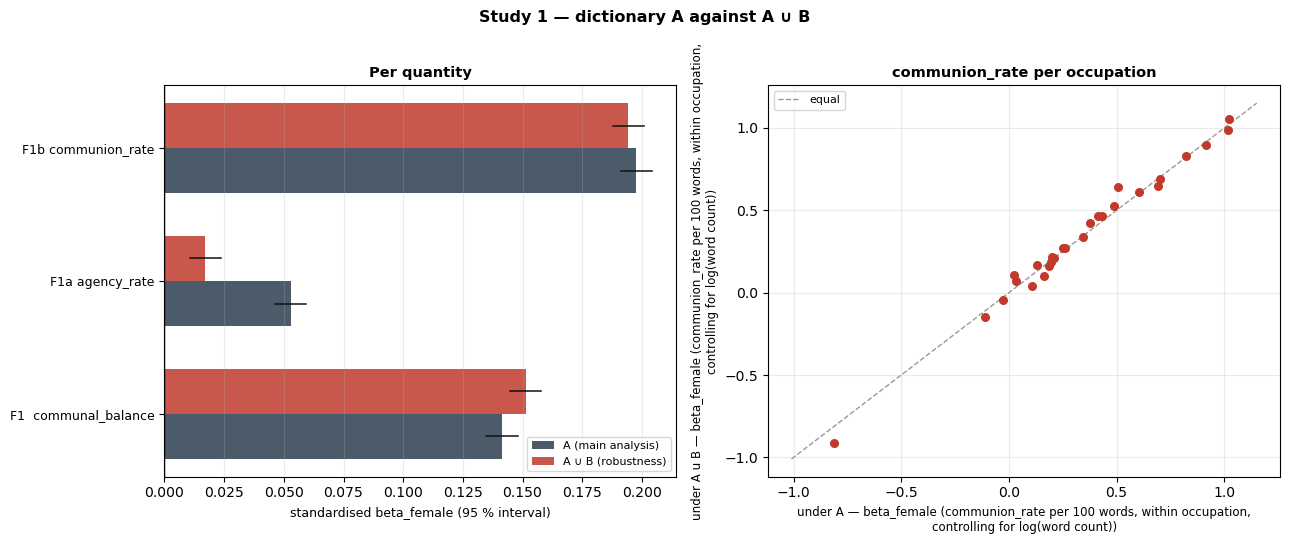

Saved to outputs\study1_results\study1_lexicon_comparison.png


In [3]:
# -- 3a. Per quantity: A against A u B ----------------------------------------
A_ES = OUTDIR / 'study1_effect_sizes.csv'
A_OCC = OUTDIR / 'study1_beta_by_occupation.csv'
A_TESTS = OUTDIR / 'study1_gap_composition_tests.csv'

missing = [str(p) for p in (A_ES, A_OCC, A_TESTS) if not p.exists()]
assert not missing, (
    "Result files of Notebook 04 are missing:\n  " + "\n  ".join(missing) +
    "\nRun 04_study1_analysis.ipynb first; this section reads its output.")

es_A = pd.read_csv(A_ES)
print(f"Dictionary A results loaded: {len(es_A)} rows from {A_ES.name}")
print(f"  estimands present: {sorted(es_A['estimand'].unique())}\n")

QMAP = {'communal_balance': 'F1  communal_balance',
        'agency_rate':            'F1a agency_rate',
        'communion_rate':         'F1b communion_rate'}

# The estimand label is the contract between the two notebooks. A lookup that
# matches nothing or more than one row raises instead of silently yielding NaN:
# an all-NaN comparison column would look like a result.
ESTIMAND = {
    'beta_raw': 'beta (raw)',
    'beta_std': 'beta (standardised)',
    'ame':      'AME (percentage points)',
    'logit_b':  'beta (logit)',
}


def pick_A(feature_label, key, startswith=False):
    """One row of the Notebook 04 table, matched by feature and estimand."""
    estimand = ESTIMAND[key]
    feat = (es_A['feature'].str.startswith(feature_label) if startswith
            else es_A['feature'] == feature_label)
    sel = es_A[feat & (es_A['estimand'] == estimand)]
    if len(sel) == 1:
        return sel.iloc[0]
    raise AssertionError(
        f"Notebook 04 table: expected exactly one row for "
        f"feature={feature_label!r}, estimand={estimand!r}, found {len(sel)}.\n"
        f"  features present: {sorted(es_A['feature'].unique())}\n"
        f"  estimands present: {sorted(es_A['estimand'].unique())}")

rows = []
for dv, label in QMAP.items():
    rAB = results_ols_AB[dv]
    for estimand, key, keys in (
            ('beta (raw)', 'beta_raw',
             ('coef', 'se', 'ci_lo', 'ci_hi')),
            ('beta (standardised)', 'beta_std',
             ('std_beta', 'std_se', 'std_ci_lo', 'std_ci_hi'))):
        a = pick_A(label, key)
        rows.append(dict(
            feature=label, estimand=estimand, pred=rAB['pred'],
            estimate_A=float(a['estimate']), se_A=float(a['se']),
            ci_lo_A=float(a['ci_lo']), ci_hi_A=float(a['ci_hi']),
            p_A=float(a['p']), d_A=float(a['d']),
            estimate_AB=rAB[keys[0]], se_AB=rAB[keys[1]],
            ci_lo_AB=rAB[keys[2]], ci_hi_AB=rAB[keys[3]], p_AB=rAB['p'],
            d_AB=(rAB['std_beta'] if key == 'beta_std' else np.nan)))

rL = results_logit_AB
for estimand, key, kE, kS, kLo, kHi, kP in (
        ('AME (percentage points)', 'ame',
         'ame', 'ame_se', 'ame_lo', 'ame_hi', 'ame_p'),
        ('beta (logit)', 'logit_b',
         'logit_b', 'logit_se', 'logit_lo', 'logit_hi', 'logit_p')):
    a = pick_A('F3', key, startswith=True)
    rows.append(dict(
        feature='F3  achievement (presence)', estimand=estimand, pred='<0',
        estimate_A=float(a['estimate']), se_A=float(a['se']),
        ci_lo_A=float(a['ci_lo']), ci_hi_A=float(a['ci_hi']),
        p_A=float(a['p']), d_A=float(a['d']),
        estimate_AB=rL[kE], se_AB=rL[kS], ci_lo_AB=rL[kLo], ci_hi_AB=rL[kHi],
        p_AB=rL[kP],
        d_AB=(rL['d'] if key == 'logit_b' else np.nan)))

cmp_q = pd.DataFrame(rows)
cmp_q['p_A_display'] = cmp_q['p_A'].apply(fmt_p)
cmp_q['p_AB_display'] = cmp_q['p_AB'].apply(fmt_p)

print("=== 3a. Per quantity ===")
print("se, ci and p always belong to the estimand on the same row.\n")
for _, r in cmp_q.iterrows():
    print(f"{r['feature']}   —   {r['estimand']}   (predicted {r['pred']})")
    print(f"  A      {r['estimate_A']:>+12.6f}   SE {r['se_A']:>11.6f}   "
          f"[{r['ci_lo_A']:>+11.6f}, {r['ci_hi_A']:>+11.6f}]   "
          f"p {r['p_A_display']}")
    print(f"  A ∪ B  {r['estimate_AB']:>+12.6f}   SE {r['se_AB']:>11.6f}   "
          f"[{r['ci_lo_AB']:>+11.6f}, {r['ci_hi_AB']:>+11.6f}]   "
          f"p {r['p_AB_display']}")
    if np.isfinite(r['estimate_A']):
        diff = r['estimate_AB'] - r['estimate_A']
        same = ((r['estimate_A'] > 0) == (r['estimate_AB'] > 0))
        print(f"  Δ      {diff:>+12.6f}   same sign: {'yes' if same else 'NO'}")
    if np.isfinite(r['d_A']) or np.isfinite(r['d_AB']):
        print(f"  d      A {r['d_A']:>+9.4f}    A ∪ B {r['d_AB']:>+9.4f}")
    print()

# -- 3b. Per occupation -------------------------------------------------------
occ_A = pd.read_csv(A_OCC)
QUANTITIES_AB = [('communal_balance',       'F1  communal_balance',       '>0'),
                 ('agency_rate',            'F1a agency_rate',            '<0'),
                 ('communion_rate',         'F1b communion_rate',         '>0'),
                 ('f3_presence',            'F3  achievement (presence)', '<0')]

occ_rows = []
for dv, label, pred in QUANTITIES_AB:
    for occ, sub in d.groupby('occupation'):
        res = smf.ols(f'{dv} ~ female + log_wc', data=sub).fit(cov_type='HC1')
        ci = res.conf_int().loc['female']
        occ_rows.append(dict(quantity=dv, label=label, pred=pred, occupation=occ,
                              beta=res.params['female'], se=res.bse['female'],
                              ci_lo=ci.iloc[0], ci_hi=ci.iloc[1],
                              p=res.pvalues['female'], n=len(sub)))
occ_AB = pd.DataFrame(occ_rows)
print(f"=== 3b. Per occupation ===")
print(f"{len(QUANTITIES_AB)} quantities × {d['occupation'].nunique()} occupations "
      f"= {len(occ_AB)} regressions with A ∪ B\n")

both = occ_AB.merge(occ_A[['quantity', 'occupation', 'beta', 'se', 'ci_lo', 'ci_hi']],
                    on=['quantity', 'occupation'], how='left',
                    suffixes=('_AB', '_A'))
print(f"  {'quantity':<28}  {'version':<7}  {'β>0':>5}  {'CI>0':>5}  {'CI<0':>5}")
print("-" * 62)
cnt_rows = []
for dv, label, pred in QUANTITIES_AB:
    sub = both[both['quantity'] == dv]
    for ver, b, lo, hi in (('A', 'beta_A', 'ci_lo_A', 'ci_hi_A'),
                            ('A ∪ B', 'beta_AB', 'ci_lo_AB', 'ci_hi_AB')):
        if sub[b].notna().sum() == 0:
            continue
        n_pos = int((sub[b] > 0).sum())
        n_up = int((sub[lo] > 0).sum())
        n_dn = int((sub[hi] < 0).sum())
        cnt_rows.append(dict(quantity=dv, label=label, version=ver, pred=pred,
                              n_occ=int(sub[b].notna().sum()), n_beta_pos=n_pos,
                              n_ci_above_zero=n_up, n_ci_below_zero=n_dn))
        print(f"  {label:<28}  {ver:<7}  {n_pos:>5}  {n_up:>5}  {n_dn:>5}")
    print()
cnt_occ = pd.DataFrame(cnt_rows)

print(f"  {'quantity':<28}  {'occupation':<20}  {'β_A':>9}  {'β_A∪B':>9}  {'Δ':>9}")
print("-" * 84)
for dv, label, pred in QUANTITIES_AB:
    sub = both[both['quantity'] == dv].sort_values('beta_A', ascending=False)
    for _, r in sub.iterrows():
        if not np.isfinite(r['beta_A']):
            continue
        print(f"  {label:<28}  {r['occupation']:<20}  {r['beta_A']:>+9.4f}  "
              f"{r['beta_AB']:>+9.4f}  {r['beta_AB'] - r['beta_A']:>+9.4f}")
    print()

# -- 3c. Composition of the occupation, section 6b with A u B ----------------
from scipy.stats import spearmanr
PERM_N, PERM_SEED = 10_000, 42
occ_meta = pd.read_csv('config/occupation_metadata_27.csv')
share = (occ_meta[['occ', 'pct_women_bls_2025', 'match']]
         .rename(columns={'occ': 'occupation', 'pct_women_bls_2025': 'pct_bls'}))
share['pct_bios'] = (d.groupby('occupation')['female'].mean() * 100).reindex(
    share['occupation']).values

# Labelled exactly as in Notebook 04, so the two test tables can be joined.
SHARE_MEASURES = (('BLS', 'pct_bls'), ('bios', 'pct_bios'))


def perm_spearman(x, y, n_perm=PERM_N, seed=PERM_SEED):
    x = np.asarray(x, float); y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    if len(x) < 4:
        return np.nan, np.nan, len(x)
    rho = spearmanr(x, y)[0]
    rng = np.random.default_rng(seed)
    yp = y.copy()
    cnt = 0
    for _ in range(n_perm):
        rng.shuffle(yp)
        if abs(spearmanr(x, yp)[0]) >= abs(rho) - 1e-12:
            cnt += 1
    return rho, (1 + cnt) / (1 + n_perm), len(x)


def wls_slope(dd_in, xcol):
    dd = dd_in.dropna(subset=[xcol, 'beta', 'se'])
    dd = dd[dd['se'] > 0]
    if len(dd) < 4:
        return (np.nan,) * 5 + (len(dd),)
    r = smf.wls('beta ~ x', data=dd.assign(x=dd[xcol]),
                weights=1.0 / dd['se'] ** 2).fit(cov_type='HC1')
    ci = r.conf_int().loc['x']
    return (float(r.params['x']), float(r.bse['x']), float(r.pvalues['x']),
            float(ci.iloc[0]), float(ci.iloc[1]), len(dd))


def holm(pvals):
    p = np.asarray(pvals, float)
    out = np.full(len(p), np.nan)
    idx = np.where(np.isfinite(p))[0]
    order = idx[np.argsort(p[idx])]
    m, run = len(order), 0.0
    for i, j in enumerate(order):
        run = max(run, (m - i) * p[j])
        out[j] = min(run, 1.0)
    return out


EXPECTED_SIGN = {'communal_balance': '+', 'agency_rate': '-',
                 'communion_rate': '+', 'f3_presence': '-',
                 'passive_ratio': '+', 'f4_presence': '+'}

# Quantities that do not depend on the dictionary. Their slope and p are
# identical under both versions, so they are taken from the Notebook 04 table
# rather than estimated again -- but they must enter the Holm family, because
# Notebook 04 corrects across six quantities per share measure and a family of
# four would yield a different correction for the same question.
NOT_DICTIONARY_DEPENDENT = [('passive_ratio', 'F2  passive_ratio'),
                            ('f4_presence',   'F4  attribution (occurrence)')]

tests_A = pd.read_csv(A_TESTS)


def pick_A_test(dv, xname):
    """One row of the Notebook 04 test table, for subset 'all'."""
    sel = tests_A[(tests_A['y'] == dv) & (tests_A['x'] == xname)
                  & (tests_A['subset'] == 'all')]
    if len(sel) == 1:
        return sel.iloc[0]
    raise AssertionError(
        f"Notebook 04 test table: expected exactly one row for y={dv!r}, "
        f"x={xname!r}, subset='all', found {len(sel)}.\n"
        f"  y present: {sorted(tests_A['y'].unique())}\n"
        f"  x present: {sorted(tests_A['x'].unique())}\n"
        f"  subset present: {sorted(tests_A['subset'].unique())}")


gap_AB = occ_AB.merge(share, on='occupation', how='left')
tests = []
for xname, xcol in SHARE_MEASURES:
    for dv, label, pred in QUANTITIES_AB:
        g = gap_AB[gap_AB['quantity'] == dv]
        rho, p_perm, n_rho = perm_spearman(g[xcol], g['beta'])
        slope, se_s, p_s, lo_s, hi_s, n_w = wls_slope(g, xcol)
        tests.append(dict(y=dv, label=label, x=xname, subset='all',
                           version='A u B', source='recomputed',
                           expected_sign=EXPECTED_SIGN[dv], n=n_rho, rho=rho,
                           p_perm=p_perm, slope=slope, se=se_s, p=p_s,
                           slope_ci_lo=lo_s, slope_ci_hi=hi_s, n_wls=n_w))
    for dv, label in NOT_DICTIONARY_DEPENDENT:
        a = pick_A_test(dv, xname)
        tests.append(dict(y=dv, label=label, x=xname, subset='all',
                           version='A u B', source='taken from dictionary A',
                           expected_sign=EXPECTED_SIGN[dv], n=a['n'],
                           rho=a['rho'], p_perm=a['p_perm'], slope=a['slope'],
                           se=a['se'], p=a['p'], slope_ci_lo=a['slope_ci_lo'],
                           slope_ci_hi=a['slope_ci_hi'], n_wls=a['n_wls']))

tests_AB = pd.DataFrame(tests)

# Holm across the six quantities within each share measure, on the p-values of
# the weighted regression -- the same family as Notebook 04, section 6b.
tests_AB['p_holm'] = np.nan
for xn, grp in tests_AB.groupby('x'):
    assert len(grp) == 6, (
        f"Holm family for share measure {xn!r} has {len(grp)} members, "
        f"expected 6 (four recomputed plus passive_ratio and F4).")
    tests_AB.loc[grp.index, 'p_holm'] = holm(grp['p'].values)

print("=== 3c. Composition of the occupation: section 6b in both versions ===")
print(f"Spearman p from {PERM_N:,} permutations (seed={PERM_SEED}); slope from "
      f"the weighted regression (1/SE^2, HC1).")
print(f"Holm corrects the p-values of the weighted regression across the six "
      f"quantities per share measure, as in Notebook 04. Only subset 'all' is")
print(f"computed here; the 'direct' subset is reported in Notebook 04 only.\n")
for xn, grp in tests_AB.groupby('x'):
    print(f"-- share of women: {xn} --")
    print(f"  {'quantity':<28}  {'ver':<6}  {'exp':>3}  {'rho':>7}  {'p_perm':>7}  "
          f"{'slope':>10}  {'p_holm':>7}  source")
    print("-" * 104)
    for _, r in grp.iterrows():
        a = pick_A_test(r['y'], xn)
        print(f"  {r['label']:<28}  {'A':<6}  {a['expected_sign']:>3}  "
              f"{a['rho']:>+7.3f}  {a['p_perm']:>7.4f}  "
              f"{a['slope']:>+10.5f}  {a['p_holm']:>7.4f}  Notebook 04")
        print(f"  {r['label']:<28}  {'A u B':<6}  {r['expected_sign']:>3}  "
              f"{r['rho']:>+7.3f}  {r['p_perm']:>7.4f}  "
              f"{r['slope']:>+10.5f}  {r['p_holm']:>7.4f}  {r['source']}")
    print()

# -- Save ---------------------------------------------------------------------
cmp_q.to_csv(OUTDIR / 'study1_lexicon_comparison.csv', index=False)
both.to_csv(OUTDIR / 'study1_lexicon_comparison_by_occupation.csv', index=False)
cnt_occ.to_csv(OUTDIR / 'study1_lexicon_comparison_counts.csv', index=False)
tests_AB.to_csv(OUTDIR / 'study1_gap_composition_tests_lexAB.csv', index=False)
print(f"Saved to {OUTDIR / 'study1_lexicon_comparison.csv'}  "
      f"({len(cmp_q)} rows)")
print(f"Saved to {OUTDIR / 'study1_lexicon_comparison_by_occupation.csv'}")
print(f"Saved to {OUTDIR / 'study1_lexicon_comparison_counts.csv'}")
print(f"Saved to {OUTDIR / 'study1_gap_composition_tests_lexAB.csv'}")

# -- Comparison figure --------------------------------------------------------
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

dd = (cmp_q[cmp_q['estimand'] == ESTIMAND['beta_std']]
      .reset_index(drop=True))
assert len(dd) == 3, (
    f"expected 3 standardised rows for the figure (F1, agency_rate, "
    f"communion_rate), found {len(dd)}: {list(dd['feature'])}")
y = np.arange(len(dd))
w = 0.34
ax = axes[0]
ax.barh(y - w / 2, dd['estimate_A'], w, color='#2c3e50', alpha=0.85,
        label='A (main analysis)')
ax.barh(y + w / 2, dd['estimate_AB'], w, color='#c0392b', alpha=0.85,
        label='A ∪ B (robustness)')
for i, r in dd.iterrows():
    ax.plot([r['ci_lo_A'], r['ci_hi_A']], [i - w / 2] * 2, color='#111111',
            linewidth=1.1)
    ax.plot([r['ci_lo_AB'], r['ci_hi_AB']], [i + w / 2] * 2, color='#111111',
            linewidth=1.1)
ax.axvline(0, color='black', linewidth=1.0)
ax.set_yticks(y)
ax.set_yticklabels(dd['feature'], fontsize=9)
ax.set_xlabel('standardised beta_female (95 % interval)', fontsize=9)
ax.set_title('Per quantity', fontsize=10.5, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(axis='x', alpha=0.25)

ax = axes[1]
sub = both[both['quantity'] == 'communion_rate']
lim_lo = float(np.nanmin([sub['beta_A'].min(), sub['beta_AB'].min()]))
lim_hi = float(np.nanmax([sub['beta_A'].max(), sub['beta_AB'].max()]))
pad = 0.05 * (lim_hi - lim_lo)
ax.plot([lim_lo - pad, lim_hi + pad], [lim_lo - pad, lim_hi + pad],
        color='#999999', linestyle='--', linewidth=1, label='equal')
ax.scatter(sub['beta_A'], sub['beta_AB'], s=30, color='#c0392b', zorder=3)
UNIT = ('beta_female (communion_rate per 100 words, within occupation,\n'
        'controlling for log(word count))')
ax.set_xlabel(f'under A — {UNIT}', fontsize=8.5)
ax.set_ylabel(f'under A u B — {UNIT}', fontsize=8.5)
ax.set_title('communion_rate per occupation', fontsize=10.5, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(alpha=0.25)

fig.suptitle('Study 1 — dictionary A against A ∪ B',
             fontsize=11.5, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(OUTDIR / 'study1_lexicon_comparison.png', dpi=180, bbox_inches='tight')
plt.show()
print(f"Saved to {OUTDIR / 'study1_lexicon_comparison.png'}")

## 4. What dictionary B contributes

Describes where the difference between the two versions comes from. Two parts:

- **4a** the share of A u B hits that arise only through B, per dimension,
  overall and by gender
- **4b** the 30 most frequent tokens that match only through B, per dimension,
  with their counts among women and men

4a is computed as a difference of counts: for each biography, hits under A u B
minus hits under A. Both counts come from the same tokenisation (section 1), so
the difference is exactly the contribution of the B-only entries.

4b counts tokens directly. A token is B-only for a dimension if it matches under
A u B but not under A. The counts are reported separately for women and men so
that a dimension whose B-only entries fall mainly in one group is visible as
such. This is descriptive and carries no test.

In [4]:
# -- 4a. Share of hits that come only through B -------------------------------
print("=== 4a. Share of A ∪ B hits arising only through B ===\n")
fem = d['female'].values.astype(bool)

share_rows = []
for dim, c_ab, c_a in (('agency', 'agency_count', 'agency_count_A'),
                       ('communion', 'communion_count', 'communion_count_A'),
                       ('achievement', 'achievement_count', 'achievement_count_A')):
    tot = d[c_ab].values.astype(float)
    bonly = tot - d[c_a].values.astype(float)
    assert (bonly >= 0).all(), f"{dim}: A has more hits than A ∪ B"
    for grp, mask in (('all', np.ones(len(d), bool)), ('women', fem), ('men', ~fem)):
        t, b = tot[mask].sum(), bonly[mask].sum()
        share_rows.append(dict(
            dimension=dim, group=grp,
            hits_AB=int(t), hits_B_only=int(b),
            share_B_only=(b / t if t > 0 else np.nan),
            pct_bios_with_B_only=float((bonly[mask] > 0).mean()),
            mean_B_only_per_bio=float(bonly[mask].mean())))

df_share = pd.DataFrame(share_rows)
print(f"  {'dimension':<13}  {'group':<6}  {'hits A∪B':>10}  {'B-only':>9}  "
      f"{'share':>7}  {'bios with ≥1':>13}")
print("-" * 70)
for _, r in df_share.iterrows():
    print(f"  {r['dimension']:<13}  {r['group']:<6}  {r['hits_AB']:>10,}  "
          f"{r['hits_B_only']:>9,}  {r['share_B_only']:>7.3f}  "
          f"{r['pct_bios_with_B_only']:>13.3f}")

# -- 4b. The 30 most frequent B-only tokens per dimension --------------------
from collections import Counter

print(f"\n=== 4b. Most frequent tokens that match only through B ===", flush=True)
texts2 = pd.read_parquet('outputs/df_preprocessed.parquet',
                         columns=['text_clean'])['text_clean'].tolist()

MATCHERS = {'agency': 'match_agency', 'communion': 'match_communion',
            'achievement': 'match_achievement'}

# Count the vocabulary once per gender, then classify the distinct token forms.
# Testing every token against every matcher would run six matcher calls per
# token over the whole corpus; the vocabulary is far smaller than the corpus.
vocab = {'women': Counter(), 'men': Counter()}
t0 = time.time()
for i, doc in enumerate(nlp_tok.pipe(texts2, batch_size=1024)):
    vocab['women' if fem[i] else 'men'].update(t.lower_ for t in doc)
print(f"  vocabulary counted in {time.time() - t0:.0f}s: "
      f"{len(set(vocab['women']) | set(vocab['men'])):,} distinct token forms")

all_forms = set(vocab['women']) | set(vocab['men'])
counters = {dim: {'women': Counter(), 'men': Counter()} for dim in MATCHERS}
for dim, fn in MATCHERS.items():
    m_ab, m_a = getattr(lex_AB, fn), getattr(lex_A, fn)
    b_only = {f for f in all_forms if m_ab(f) and not m_a(f)}
    for grp in ('women', 'men'):
        counters[dim][grp] = Counter({f: vocab[grp][f] for f in b_only
                                       if vocab[grp][f]})
    print(f"  {dim:<12}: {len(b_only):,} distinct B-only forms in the corpus")

tok_rows = []
for dim in MATCHERS:
    tot = counters[dim]['women'] + counters[dim]['men']
    print(f"\n── {dim}: {len(tot):,} distinct B-only tokens, "
          f"{sum(tot.values()):,} hits ──")
    print(f"  {'token':<22}  {'total':>8}  {'women':>8}  {'men':>8}  {'share w':>8}")
    print("-" * 62)
    for tok, n in tot.most_common(30):
        nw, nm = counters[dim]['women'][tok], counters[dim]['men'][tok]
        tok_rows.append(dict(dimension=dim, token=tok, n_total=n,
                             n_women=nw, n_men=nm,
                             share_women=(nw / n if n else np.nan)))
        print(f"  {tok:<22}  {n:>8,}  {nw:>8,}  {nm:>8,}  "
              f"{(nw / n if n else np.nan):>8.3f}")

df_tokens = pd.DataFrame(tok_rows)

# -- Descriptives of both versions, side by side -----------------------------
from scipy.stats import pearsonr

print(f"\n=== 4c. Descriptives of both versions ===")
desc_rows = []
for col, a_col in (('agency_count', 'agency_count_A'),
                   ('communion_count', 'communion_count_A'),
                   ('achievement_count', 'achievement_count_A')):
    a = d[a_col].values.astype(float)
    b = d[col].values.astype(float)
    desc_rows.append(dict(column=col, mean_A=a.mean(), sd_A=a.std(),
                           mean_AB=b.mean(), sd_AB=b.std(),
                           r_A_AB=float(pearsonr(a, b)[0]),
                           pct_zero_A=float((a == 0).mean()),
                           pct_zero_AB=float((b == 0).mean())))
for col, a_col in (('communal_balance', None), ('agency_rate', None),
                   ('communion_rate', None), ('achievement_verb_rate', None)):
    b = d[col].values.astype(float)
    desc_rows.append(dict(column=col, mean_A=np.nan, sd_A=np.nan,
                           mean_AB=b.mean(), sd_AB=b.std(), r_A_AB=np.nan,
                           pct_zero_A=np.nan,
                           pct_zero_AB=float((b == 0).mean())))
df_desc = pd.DataFrame(desc_rows)
print(f"  {'column':<26}  {'mean A':>9}  {'mean A∪B':>10}  {'r':>7}  "
      f"{'zero A':>7}  {'zero A∪B':>9}")
print("-" * 80)
for _, r in df_desc.iterrows():
    print(f"  {r['column']:<26}  {r['mean_A']:>9.4f}  {r['mean_AB']:>10.4f}  "
          f"{r['r_A_AB']:>7.4f}  {r['pct_zero_A']:>7.3f}  {r['pct_zero_AB']:>9.3f}")

df_desc.to_csv(OUTDIR / 'study1_lexicon_descriptives.csv', index=False)
df_share.to_csv(OUTDIR / 'study1_lexicon_b_only_share.csv', index=False)
df_tokens.to_csv(OUTDIR / 'study1_lexicon_b_only_tokens.csv', index=False)
print(f"\nSaved to {OUTDIR / 'study1_lexicon_descriptives.csv'}")
print(f"Saved to {OUTDIR / 'study1_lexicon_b_only_share.csv'}")
print(f"Saved to {OUTDIR / 'study1_lexicon_b_only_tokens.csv'} "
      f"({len(df_tokens)} rows)")

del texts2
_ = gc.collect()

=== 4a. Share of A ∪ B hits arising only through B ===

  dimension      group     hits A∪B     B-only    share   bios with ≥1
----------------------------------------------------------------------
  agency         all        585,686    220,546    0.377          0.372
  agency         women      273,689    106,867    0.390          0.379
  agency         men        311,997    113,679    0.364          0.367
  communion      all        899,047     75,081    0.084          0.156
  communion      women      460,244     35,232    0.077          0.157
  communion      men        438,803     39,849    0.091          0.155
  achievement    all         51,751      3,525    0.068          0.008
  achievement    women       23,639      1,417    0.060          0.007
  achievement    men         28,112      2,108    0.075          0.009

=== 4b. Most frequent tokens that match only through B ===
  vocabulary counted in 116s: 333,539 distinct token forms
  agency      : 524 distinct B-only forms in

## 5. Study 1 without pronouns and modal verbs

The dictionaries of Pietraszkiewicz et al. count pronouns and modal verbs as
hits: "we", "us", "our" and their forms on the communal side, "will" and
"should" with their contractions on the agentic side. Decision D1 of Study 2
never replaces those words, because replacing them changes the addressee of a
sentence rather than its wording. This section asks what Study 1 looks like
when they are left out of the count as well.

- **Question:** Do the Study 1 findings hold when the pronouns and modal verbs
  of D1 are removed from the hits and from the denominator?
- **Expectation:** none directional; the question is whether the gap rests on
  those words.
- **Status:** robustness check, added on 2026-10-18 after the Arm 1 results.
  The counting follows section 1, the models follow section 2, so only the set
  of words changes.
- **Unit and test:** biography;
  `feature ~ female + C(occupation, Treatment("professor")) + log(word count)`
  with HC1, as in notebook 04 and in section 2.
- **Output:** `outputs/df_features_nofw.parquet` (the rates per biography) and
  `outputs/study1_results/study1_without_function_words.csv` (the models, next
  to the main analysis).

Two things change against section 1. The hits are counted without the D1
function words, and the denominator is the word count without those words as
well, so a biography that uses "we" often is not rewarded with a longer
denominator. The rate is again words of the dictionary per 100 words.

In [5]:
# -- 5a. Counting without the D1 function words ------------------------------

# The list is the one of Study 2, decision D1, read from the module that the
# manipulation uses, so the two notebooks cannot drift apart.
from src.substitution_v2 import is_function_word_kept

# A trial run can work on a sample; the full run leaves this at None.
TRIAL_SAMPLE = None

# Section 1 frees its texts after the recount, so they are read again here,
# one column only, and freed at the end of this section.
_frame = df_A if TRIAL_SAMPLE is None else df_A.head(TRIAL_SAMPLE)
_texts = pd.read_parquet('outputs/df_preprocessed.parquet',
                         columns=['text_clean'])['text_clean']
if TRIAL_SAMPLE is not None:
    _texts = _texts.head(TRIAL_SAMPLE)
_texts = _texts.tolist()
assert len(_texts) == len(_frame), "texts and features differ in length"
print(f"biographies counted: {len(_frame):,}"
      + ("" if TRIAL_SAMPLE is None else f"  (trial sample of {TRIAL_SAMPLE})"))

_t0 = time.time()
_rows = []
for _idx, _doc in enumerate(nlp_tok.pipe(_texts, batch_size=256)):
    _tokens = [t.lower_ for t in _doc]
    _n_fw_tokens = sum(1 for t in _tokens if is_function_word_kept(t))
    _communion = [t for t in _tokens if lex_A.match_communion(t)]
    _agency = [t for t in _tokens if lex_A.match_agency(t)]
    # Multi-word communion matches hold no function words, so they stay in.
    _n_multi = count_multiword_communion(str(_texts[_idx]).lower(),
                                         lex_A.multi_word_communion)
    _rows.append((
        len(_communion) + _n_multi,
        sum(1 for t in _communion if is_function_word_kept(t)),
        len(_agency),
        sum(1 for t in _agency if is_function_word_kept(t)),
        _n_fw_tokens,
        len(_tokens)))
    if (_idx + 1) % 50000 == 0:
        print(f"  {_idx + 1:,} biographies  {time.time() - _t0:,.0f}s")
print(f"counting done in {time.time() - _t0:,.0f}s")

_counts = pd.DataFrame(_rows, index=_frame.index,
                       columns=["communion_hits", "communion_fw",
                                "agency_hits", "agency_fw",
                                "n_function_word_tokens", "n_tokens"])
df_nofw = _frame[["occupation", "gender_label", "word_count",
                  "communion_count", "agency_count"]].copy()
df_nofw = pd.concat([df_nofw, _counts], axis=1)

# Control: the recounted hits under A have to be the stored ones of notebook 03.
_dev_communion = int((df_nofw["communion_hits"]
                      - df_nofw["communion_count"]).abs().max())
_dev_agency = int((df_nofw["agency_hits"] - df_nofw["agency_count"]).abs().max())
print(f"control recounted hits against notebook 03: communion {_dev_communion}, "
      f"agency {_dev_agency} (expected 0)")
if _dev_communion or _dev_agency:
    raise AssertionError(
        "The hits counted here differ from the stored counts of notebook 03, "
        "so the two do not use the same dictionary or the same tokenisation.")

# The denominator without the function words. A biography made of nothing but
# those words would leave no denominator, so the floor is one word.
df_nofw["word_count_clean"] = (df_nofw["word_count"]
                               - df_nofw["n_function_word_tokens"]).clip(lower=1)
_n_floor = int((df_nofw["word_count"]
                - df_nofw["n_function_word_tokens"] < 1).sum())
print(f"biographies whose cleaned word count would fall below one: {_n_floor}")

df_nofw["communion_count_nofw"] = (df_nofw["communion_hits"]
                                   - df_nofw["communion_fw"])
df_nofw["agency_count_nofw"] = df_nofw["agency_hits"] - df_nofw["agency_fw"]
df_nofw["communion_rate_nofw"] = (df_nofw["communion_count_nofw"]
                                  / df_nofw["word_count_clean"] * 100)
df_nofw["agency_rate_nofw"] = (df_nofw["agency_count_nofw"]
                               / df_nofw["word_count_clean"] * 100)
df_nofw["communal_balance_nofw"] = (df_nofw["communion_rate_nofw"]
                                    - df_nofw["agency_rate_nofw"])

print()
print(f"  {'quantity':<28} {'with D1':>12} {'without D1':>12} {'share left':>11}")
print("  " + "-" * 66)
for _label, _with, _without in (
        ("communion hits", "communion_hits", "communion_count_nofw"),
        ("agency hits", "agency_hits", "agency_count_nofw")):
    _a, _b = df_nofw[_with].sum(), df_nofw[_without].sum()
    print(f"  {_label:<28} {_a:>12,} {_b:>12,} {_b / _a:>10.1%}")
print(f"  {'words in the denominator':<28} {df_nofw['word_count'].sum():>12,} "
      f"{df_nofw['word_count_clean'].sum():>12,} "
      f"{df_nofw['word_count_clean'].sum() / df_nofw['word_count'].sum():>10.1%}")

# -- 5b. The models of section 2, on the quantities without D1 ---------------
_d = df_nofw.copy()
_d["female"] = (_d["gender_label"] == "Female").astype(int)
_d["log_wc"] = np.log(_d["word_count"])
# The last field is the row of the main analysis, as study1_effect_sizes.csv
# names it in its column 'feature'.
_specs = [("communal_balance_nofw", "F1  communal_balance", ">0",
           "F1  communal_balance"),
          ("agency_rate_nofw", "F1a agency_rate", "<0", "F1a agency_rate"),
          ("communion_rate_nofw", "F1b communion_rate", ">0",
           "F1b communion_rate")]
_main = pd.read_csv(OUTDIR / "study1_effect_sizes.csv")

print()
print("=== 5b. OLS without the D1 function words, HC1 robust standard errors ===")
_rows_models = []
for _dv, _label, _sign, _main_name in _specs:
    _res = smf.ols(f"{_dv} ~ {BASE}", data=_d).fit(cov_type="HC1")
    _sd = _d[_dv].std()
    _coef, _se = _res.params["female"], _res.bse["female"]
    _ci = _res.conf_int().loc["female"]
    print(f"{_label}   (SD of the DV = {_sd:.4f})")
    print(f"  raw           beta = {_coef:+.6f}   SE = {_se:.6f}   "
          f"95% CI [{_ci.iloc[0]:+.6f}, {_ci.iloc[1]:+.6f}]")
    print(f"  standardised  beta = {_coef / _sd:+.6f}")
    print(f"  p = {fmt_p(_res.pvalues['female'])}   expected_sign = {_sign}   "
          f"n = {int(_res.nobs):,}")
    _row = {"quantity": _dv, "label": _label, "expected_sign": _sign,
            "n": int(_res.nobs), "sd_dv": float(_sd),
            "beta": float(_coef), "se": float(_se),
            "ci_lo": float(_ci.iloc[0]), "ci_hi": float(_ci.iloc[1]),
            "p": float(_res.pvalues["female"]),
            "std_beta": float(_coef / _sd), "r2": float(_res.rsquared)}
    _match = _main[(_main["feature"] == _main_name)
                   & (_main["estimand"] == "beta (raw)")]
    if len(_match) == 1:
        _row["beta_main_analysis"] = float(_match.iloc[0]["estimate"])
        _row["p_main_analysis"] = float(_match.iloc[0]["p"])
        print(f"  main analysis beta = {_row['beta_main_analysis']:+.6f}   "
              f"p = {fmt_p(_row['p_main_analysis'])}")
    else:
        print(f"  the main analysis holds {len(_match)} rows for "
              f"{_main_name!r}, so no comparison is printed")
    print()
    _rows_models.append(_row)
df_nofw_models = pd.DataFrame(_rows_models)

# -- 5c. Save ----------------------------------------------------------------
_parquet = Path("outputs/df_features_nofw.parquet")
_csv = OUTDIR / "study1_without_function_words.csv"
for _path in (_parquet, _csv):
    if _path.exists():
        raise AssertionError(
            f"{_path} already exists; this section does not overwrite a saved "
            f"output. Move the old file aside before running it again.")
df_nofw.to_parquet(_parquet, index=True)
df_nofw_models.to_csv(_csv, index=False, encoding="utf-8")
print(f"Saved to {_parquet} ({len(df_nofw):,} rows)")
print(f"Saved to {_csv} ({len(df_nofw_models)} rows)")

del _counts, _rows, _texts
_ = gc.collect()

biographies counted: 393,977
  50,000 biographies  56s
  100,000 biographies  116s
  150,000 biographies  180s
  200,000 biographies  225s
  250,000 biographies  246s
  300,000 biographies  267s
  350,000 biographies  288s
counting done in 306s
control recounted hits against notebook 03: communion 0, agency 0 (expected 0)
biographies whose cleaned word count would fall below one: 0

  quantity                          with D1   without D1  share left
  ------------------------------------------------------------------
  communion hits                    823,966      823,936     100.0%
  agency hits                       365,140      352,410      96.5%
  words in the denominator       23,922,073   23,909,179      99.9%

=== 5b. OLS without the D1 function words, HC1 robust standard errors ===
F1  communal_balance   (SD of the DV = 3.7204)
  raw           beta = +0.525529   SE = 0.012341   95% CI [+0.501341, +0.549716]
  standardised  beta = +0.141256
  p = < 1e-300   expected_sign = >0 